In [23]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

# Depuis la racine du projet ou le dossier src.
dataset = Path("dataset_thomas_normalised")
if not dataset.exists():
    dataset = Path("../dataset_thomas_normalised")

class_names = sorted(folder.name for folder in dataset.iterdir() if folder.is_dir())
sequences, labels = [], []
for label, name in enumerate(class_names):
    for file in sorted((dataset / name).glob("*.csv")):
        sequences.append(np.loadtxt(file, delimiter=",", skiprows=1, usecols=(0, 1, 3, 4), dtype=np.float32))
        labels.append(label)

X = np.stack(sequences)  # (gestes, mesures, axes X/Y/GX/GY)
y = np.array(labels)
print("Classes :", dict(enumerate(class_names)))
print("X :", X.shape, "| y :", y.shape)

Classes : {0: 'circle', 1: 'hor', 2: 'nothing', 3: 'ver'}
X : (800, 75, 4) | y : (800,)


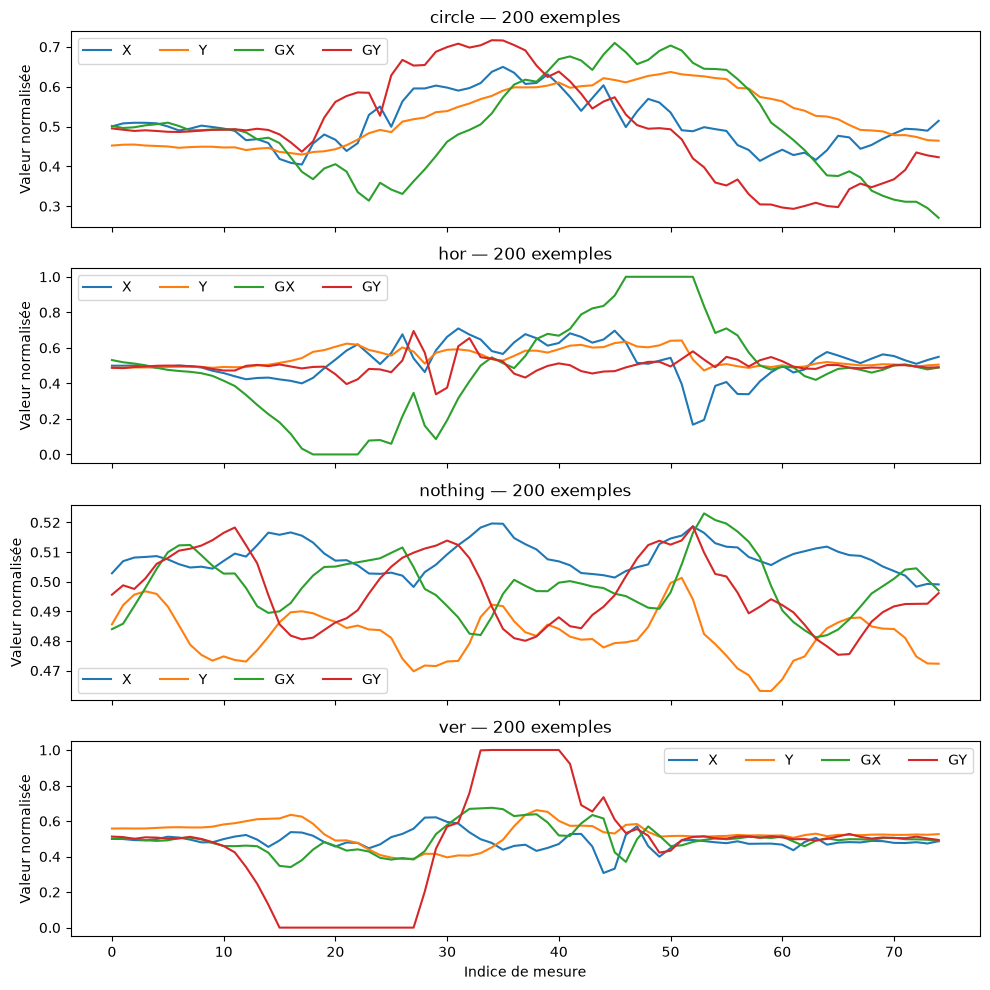

In [24]:
# Afficher un exemple par classe avec les quatre axes retenus.
fig, axes = plt.subplots(len(class_names), 1, figsize=(10, 10), sharex=True)
for label, ax in enumerate(np.atleast_1d(axes)):
    example = X[y == label][0]
    ax.plot(example)
    ax.set_title(f"{class_names[label]} — {sum(y == label)} exemples")
    ax.set_ylabel("Valeur normalisée")
    ax.legend(["X", "Y", "GX", "GY"], ncol=4)
axes[-1].set_xlabel("Indice de mesure")
plt.tight_layout()
plt.show()

In [25]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print("Entraînement :", X_train.shape, "| Test :", X_test.shape)


Entraînement : (640, 75, 4) | Test : (160, 75, 4)


In [26]:
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

torch.manual_seed(42)

train_x = torch.tensor(X_train, dtype=torch.float32).transpose(1, 2)
test_x = torch.tensor(X_test, dtype=torch.float32).transpose(1, 2)
train_y = torch.tensor(y_train, dtype=torch.long)
test_y = torch.tensor(y_test, dtype=torch.long)
loader = DataLoader(TensorDataset(train_x, train_y), batch_size=32, shuffle=True)

model = nn.Sequential(
    nn.Conv1d(4, 16, kernel_size=5, padding=2),
    nn.ReLU(),
    nn.MaxPool1d(2),
    nn.Conv1d(16, 32, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.AdaptiveAvgPool1d(4),
    nn.Flatten(),
    nn.Linear(32 * 4, len(class_names)),
)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss()

history = {"loss": [], "accuracy": []}
model.train()

for epoch in range(30):
    total_loss, correct = 0, 0
    for batch_x, batch_y in loader:
        optimizer.zero_grad()
        logits = model(batch_x)
        loss = criterion(logits, batch_y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(batch_y)
        correct += (logits.argmax(dim=1) == batch_y).sum().item()
    history["loss"].append(total_loss / len(train_y))
    history["accuracy"].append(correct / len(train_y))
    if (epoch + 1) % 5 == 0:
        print(f"Époque {epoch + 1}/30 — perte : {total_loss / len(train_y):.4f}")

model.eval()
with torch.no_grad():
    predictions = model(test_x).argmax(dim=1)
    accuracy = (predictions == test_y).float().mean().item()
print(f"Précision sur le test : {accuracy:.1%}")


Époque 5/30 — perte : 1.0016
Époque 10/30 — perte : 0.3199
Époque 15/30 — perte : 0.1469
Époque 20/30 — perte : 0.0931
Époque 25/30 — perte : 0.0674
Époque 30/30 — perte : 0.0543
Précision sur le test : 98.8%


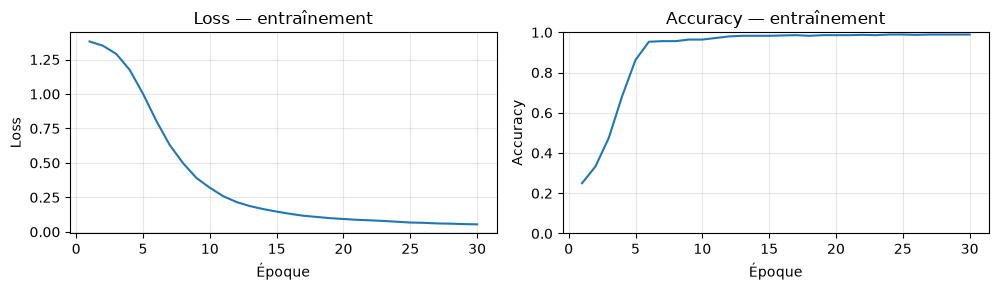

In [27]:
epochs = range(1, len(history["loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for ax, metric, title in zip(axes, ["loss", "accuracy"], ["Loss", "Accuracy"]):
    ax.plot(epochs, history[metric])
    ax.set(xlabel="Époque", ylabel=title, title=f"{title} — entraînement")
    ax.grid(alpha=0.3)
axes[1].set_ylim(0, 1)
plt.tight_layout()
plt.show()


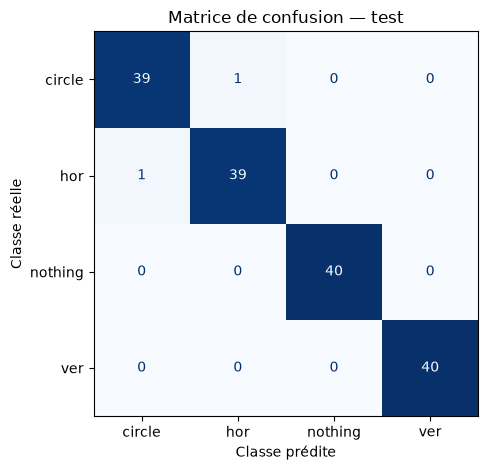

In [28]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    test_y.cpu().numpy(), predictions.cpu().numpy(),
    labels=range(len(class_names)), display_labels=class_names,
    cmap="Blues", colorbar=False,
)
plt.xlabel("Classe prédite")
plt.ylabel("Classe réelle")
plt.title("Matrice de confusion — test")
plt.tight_layout()
plt.show()


In [29]:
import tensorflow as tf

# Reprendre les poids du CNN PyTorch, sans réentraînement.
weights = [layer.weight.detach().cpu().numpy() for layer in (model[0], model[3], model[7])]
biases = [layer.bias.detach().cpu().numpy() for layer in (model[0], model[3], model[7])]

class TensorFlowCNN(tf.Module):
    @tf.function(input_signature=[tf.TensorSpec([1, X_train.shape[1], 4], tf.float32)])
    def __call__(self, x):
        for i in range(2):
            x = tf.nn.conv1d(x, weights[i].transpose(2, 1, 0), stride=1, padding="SAME")
            x = tf.nn.relu(x + biases[i])
            if i == 0:
                x = tf.nn.max_pool1d(x, ksize=2, strides=2, padding="VALID")
        # Même découpage que AdaptiveAvgPool1d(4) dans PyTorch.
        n = x.shape[1]
        x = tf.concat([tf.reduce_mean(x[:, i*n//4:((i+1)*n+3)//4, :], axis=1, keepdims=True)
                       for i in range(4)], axis=1)
        x = tf.reshape(tf.transpose(x, [0, 2, 1]), [1, -1])
        return tf.matmul(x, weights[2].T) + biases[2]

tf_model = TensorFlowCNN()

I0000 00:00:1794926298.110037 1865167 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794926298.144007 1865167 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794926299.522352 1865167 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794926299.522588 1865167 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [30]:
converter = tf.lite.TFLiteConverter.from_concrete_functions(
    [tf_model.__call__.get_concrete_function()], tf_model
)
float_model = converter.convert()

# Calibrer uniquement avec les données d'entraînement.
def representative_data():
    for sample in X_train:
        yield [sample[None].astype(np.float32)]

converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.representative_dataset = representative_data
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
converter.inference_input_type = tf.int8
converter.inference_output_type = tf.int8
int8_model = converter.convert()

output_dir = dataset.resolve().parent / "models"
output_dir.mkdir(exist_ok=True)
(output_dir / "cnn1d_float32.tflite").write_bytes(float_model)
(output_dir / "cnn1d_int8.tflite").write_bytes(int8_model)
print(f"Float32 : {len(float_model)/1024:.1f} Ko | INT8 : {len(int8_model)/1024:.1f} Ko")
print(f"Réduction : {1 - len(int8_model)/len(float_model):.1%}")


INFO:tensorflow:Assets written to: /tmp/tmp2itaxul9/assets


E0000 00:00:1794926299.826699 1865167 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
INFO:tensorflow:Assets written to: /tmp/tmp2itaxul9/assets


INFO:tensorflow:Assets written to: /tmp/tmpzk7fw7u6/assets


W0000 00:00:1794926299.934727 1865167 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1794926299.934739 1865167 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1794926299.934964 1865167 reader.cc:83] Reading SavedModel from: /tmp/tmp2itaxul9
I0000 00:00:1794926299.935216 1865167 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1794926299.935220 1865167 reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmp2itaxul9
I0000 00:00:1794926299.937215 1865167 mlir_graph_optimization_pass.cc:437] MLIR V1 optimization pass is not enabled
I0000 00:00:1794926299.937393 1865167 loader.cc:236] Restoring SavedModel bundle.
I0000 00:00:1794926299.941492 1865167 loader.cc:220] Running initialization op on SavedModel bundle at path: /tmp/tmp2itaxul9
I0000 00:00:1794926299.944483 1865167 loader.cc:471] SavedModel load for tags { serve }; Status: success: OK. Took 9525 microseconds.
I0000 00:00:1794926299.951785 1865167 

Float32 : 14.4 Ko | INT8 : 9.4 Ko
Réduction : 34.6%


W0000 00:00:1794926300.034722 1865167 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1794926300.034745 1865167 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1794926300.034836 1865167 reader.cc:83] Reading SavedModel from: /tmp/tmpzk7fw7u6
I0000 00:00:1794926300.035036 1865167 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1794926300.035041 1865167 reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmpzk7fw7u6
I0000 00:00:1794926300.036234 1865167 loader.cc:236] Restoring SavedModel bundle.
I0000 00:00:1794926300.040331 1865167 loader.cc:220] Running initialization op on SavedModel bundle at path: /tmp/tmpzk7fw7u6
I0000 00:00:1794926300.043300 1865167 loader.cc:471] SavedModel load for tags { serve }; Status: success: OK. Took 8470 microseconds.
I0000 00:00:1794926300.073270 1865167 flatbuffer_export.cc:4302] Estimated count of arithmetic ops: 0.166 M  ops, equivalently 0.083 M  MACs
fully_quantiz

In [31]:
import json

# Exporter le modèle INT8 existant pour PlatformIO.
project_dir = dataset.resolve().parent
model_bytes = (project_dir / "models/cnn1d_int8.tflite").read_bytes()
interpreter = tf.lite.Interpreter(model_content=model_bytes)
interpreter.allocate_tensors()
input_info = interpreter.get_input_details()[0]
output_info = interpreter.get_output_details()[0]
assert input_info["dtype"] == output_info["dtype"] == np.int8
_, samples, channels = input_info["shape"]
input_scale, input_zero = input_info["quantization"]
output_scale, output_zero = output_info["quantization"]
labels = ", ".join(json.dumps(name) for name in class_names)

header = f"""#pragma once

// TensorFlow Lite Micro : entrée INT8 [1, {samples}, {channels}], ordre X, Y, GX, GY.
// Appliquer la même normalisation et la même cadence que le dataset.
// Quantification : clamp(round(valeur_normalisee / scale) + zero_point, -128, 127).
extern const unsigned char g_gesture_model[];
extern const unsigned int g_gesture_model_len;
constexpr int kGestureSamples = {samples};
constexpr int kGestureChannels = {channels};
constexpr int kGestureClasses = {len(class_names)};
constexpr float kGestureInputScale = {input_scale:.10e}f;
constexpr int kGestureInputZeroPoint = {input_zero};
constexpr float kGestureOutputScale = {output_scale:.10e}f;
constexpr int kGestureOutputZeroPoint = {output_zero};
constexpr const char* kGestureLabels[] = {{{labels}}};
"""
hex_rows = [", ".join(f"0x{byte:02x}" for byte in model_bytes[i:i+12])
            for i in range(0, len(model_bytes), 12)]
source = '#include "gesture_model.h"\n\nalignas(16) const unsigned char g_gesture_model[] = {\n'
source += "\n".join("    " + row + "," for row in hex_rows)
source += '\n};\nconst unsigned int g_gesture_model_len = sizeof(g_gesture_model);\n'
(project_dir / "include/gesture_model.h").write_text(header)
(project_dir / "src/gesture_model.cpp").write_text(source)
print(f"Export ESP32 : {len(model_bytes)} octets — include/gesture_model.h et src/gesture_model.cpp")


Export ESP32 : 9632 octets — include/gesture_model.h et src/gesture_model.cpp


/home/thomas/Documents/PlatformIO/Projects/IOT_Baguette_Magique/.venv/lib/python3.11/site-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
